In [1]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

# Read the uploaded CSV file
filename = next(iter(uploaded))
df = pd.read_csv(filename, encoding="utf-8")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nHate speech label distribution:")
print(df["hate"].value_counts().sort_index())

print("\nTopic categories:")
print(df["category"].value_counts())

print("\nDuplicate rows:", df.duplicated().sum())


Saving Bengali hate speech .csv to Bengali hate speech .csv
Dataset loaded successfully!
Dataset shape: (30000, 3)

Columns: ['sentence', 'hate', 'category']

First five rows:


,sentence,hate,category
0,যত্তসব পাপন শালার ফাজলামী!!!!!,1,sports
1,পাপন শালা রে রিমান্ডে নেওয়া দরকার,1,sports
2,জিল্লুর রহমান স্যারের ছেলে এতো বড় জারজ হবে এটা...,1,sports
3,শালা লুচ্চা দেখতে পাঠার মত দেখা যায়,1,sports
4,তুই তো শালা গাজা খাইছচ।তুর মার হেডায় খেলবে সাকিব,1,sports



Missing values:
sentence    0
hate        0
category    0
dtype: int64

Hate speech label distribution:
hate
0    20000
1    10000
Name: count, dtype: int64

Topic categories:
category
crime                      4763
entertainment              4527
sports                     4406
religion                   4370
Meme, TikTok and others    4236
politics                   3987
celebrity                  3711
Name: count, dtype: int64

Duplicate rows: 54


In [2]:

import pandas as pd

# Keep the columns needed for our first experiment
data = df[["sentence", "hate", "category"]].copy()

# Remove rows without usable text or labels
data = data.dropna(subset=["sentence", "hate"])
data["sentence"] = data["sentence"].astype(str).str.strip()
data = data[data["sentence"] != ""]

# Check for identical sentences with different labels
label_counts = data.groupby("sentence")["hate"].nunique()
conflicting_sentences = label_counts[label_counts > 1]

print("Sentences with conflicting labels:",
      len(conflicting_sentences))

# Remove exact duplicate rows
data = data.drop_duplicates(
    subset=["sentence", "hate", "category"]
).reset_index(drop=True)

print("\nRows after removing exact duplicates:", len(data))
print("\nLabel distribution:")
print(data["hate"].value_counts().sort_index())

print("\nClass proportions:")
print(data["hate"].value_counts(normalize=True).sort_index())

print("\nDataset preparation complete!")


Sentences with conflicting labels: 21

Rows after removing exact duplicates: 29946

Label distribution:
hate
0    19965
1     9981
Name: count, dtype: int64

Class proportions:
hate
0    0.6667
1    0.3333
Name: proportion, dtype: float64

Dataset preparation complete!


In [3]:

from sklearn.model_selection import train_test_split

X = data["sentence"]
y = data["hate"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Training samples: 23956
Testing samples: 5990

Training label distribution:
hate
0    15971
1     7985
Name: count, dtype: int64

Testing label distribution:
hate
0    3994
1    1996
Name: count, dtype: int64


In [4]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        max_features=100000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-hate", "Hate speech"],
    digits=4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.8896

Classification report:
              precision    recall  f1-score   support

    Non-hate     0.9182    0.9161    0.9172      3994
 Hate speech     0.8329    0.8367    0.8348      1996

    accuracy                         0.8896      5990
   macro avg     0.8756    0.8764    0.8760      5990
weighted avg     0.8898    0.8896    0.8897      5990


Confusion matrix:
[[3659  335]
 [ 326 1670]]


In [5]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

results = []
trained_models = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            max_features=100000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    print("Training:", name)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Hate Precision": precision_score(
            y_test, predictions, pos_label=1
        ),
        "Hate Recall": recall_score(
            y_test, predictions, pos_label=1
        ),
        "Hate F1": f1_score(
            y_test, predictions, pos_label=1
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df.round(4))

# Detailed results for the best model by macro F1
best_name = results_df.loc[0, "Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("\nBest model by macro F1:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Non-hate", "Hate speech"],
    digits=4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, best_predictions))


Training: Naive Bayes
Training: Logistic Regression
Training: Linear SVM

MODEL COMPARISON


,Model,Accuracy,Hate Precision,Hate Recall,Hate F1,Macro F1
0,Linear SVM,0.8928,0.8430,0.8337,0.8383,0.8791
1,Logistic Regression,0.8896,0.8329,0.8367,0.8348,0.8760
2,Naive Bayes,0.8529,0.8324,0.6994,0.7601,0.8270



Best model by macro F1: Linear SVM

Classification report:
              precision    recall  f1-score   support

    Non-hate     0.9173    0.9224    0.9199      3994
 Hate speech     0.8430    0.8337    0.8383      1996

    accuracy                         0.8928      5990
   macro avg     0.8801    0.8780    0.8791      5990
weighted avg     0.8925    0.8928    0.8927      5990


Confusion matrix:
[[3684  310]
 [ 332 1664]]


In [6]:

# Check whether identical sentences appear in both sets

train_sentences = set(X_train)
test_sentences = set(X_test)

overlap = train_sentences.intersection(test_sentences)

print("Unique training sentences:", len(train_sentences))
print("Unique test sentences:", len(test_sentences))
print("Sentences appearing in BOTH sets:", len(overlap))

# Check repeated sentences with conflicting hate labels
label_counts = data.groupby("sentence")["hate"].nunique()

print(
    "Sentences with conflicting labels:",
    int((label_counts > 1).sum())
)


Unique training sentences: 23886
Unique test sentences: 5985
Sentences appearing in BOTH sets: 28
Sentences with conflicting labels: 21


In [7]:

results_df.to_csv(
    "bangla_hate_speech_model_comparison_initial.csv",
    index=False
)

from google.colab import files
files.download(
    "bangla_hate_speech_model_comparison_initial.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

from sklearn.model_selection import train_test_split

# Identify sentences with inconsistent hate labels
label_counts = data.groupby("sentence")["hate"].nunique()
conflicting_sentences = label_counts[label_counts > 1]

# Exclude conflicting sentences from this experiment
clean_data = data[
    ~data["sentence"].isin(conflicting_sentences.index)
].copy()

# Keep one row per unique sentence
clean_data = clean_data.drop_duplicates(
    subset=["sentence"]
).reset_index(drop=True)

X_clean = clean_data["sentence"]
y_clean = clean_data["hate"].astype(int)

# Split unique sentences, keeping label proportions similar
X_train_clean, X_test_clean, y_train_clean, y_test_clean = (
    train_test_split(
        X_clean,
        y_clean,
        test_size=0.20,
        random_state=42,
        stratify=y_clean
    )
)

print("Clean dataset size:", len(clean_data))
print("Training samples:", len(X_train_clean))
print("Testing samples:", len(X_test_clean))

print(
    "Overlap:",
    len(set(X_train_clean).intersection(set(X_test_clean)))
)

print("\nTraining labels:")
print(y_train_clean.value_counts())

print("\nTesting labels:")
print(y_test_clean.value_counts())


Clean dataset size: 29822
Training samples: 23857
Testing samples: 5965
Overlap: 0

Training labels:
hate
0    15907
1     7950
Name: count, dtype: int64

Testing labels:
hate
0    3977
1    1988
Name: count, dtype: int64


In [9]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

classifiers = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

clean_results = []
clean_models = {}

for name, classifier in classifiers.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            max_features=100000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train_clean, y_train_clean)
    pred = pipeline.predict(X_test_clean)

    clean_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_clean, pred),
        "Hate Precision": precision_score(
            y_test_clean, pred, zero_division=0
        ),
        "Hate Recall": recall_score(
            y_test_clean, pred, zero_division=0
        ),
        "Hate F1": f1_score(
            y_test_clean, pred, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_clean, pred, average="macro",
            zero_division=0
        )
    })

    clean_models[name] = pipeline

clean_results_df = pd.DataFrame(clean_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(clean_results_df.round(4))


,Model,Accuracy,Hate Precision,Hate Recall,Hate F1,Macro F1
0,Linear SVM,0.8914,0.8404,0.8320,0.8362,0.8775
1,Logistic Regression,0.8899,0.8332,0.8370,0.8351,0.8762
2,Naive Bayes,0.8483,0.8332,0.6811,0.7495,0.8204


FINAL LINEAR SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Non-hate     0.9164    0.9210    0.9187      3977
 Hate speech     0.8404    0.8320    0.8362      1988

    accuracy                         0.8914      5965
   macro avg     0.8784    0.8765    0.8775      5965
weighted avg     0.8911    0.8914    0.8912      5965

Confusion matrix:
[[3663  314]
 [ 334 1654]]


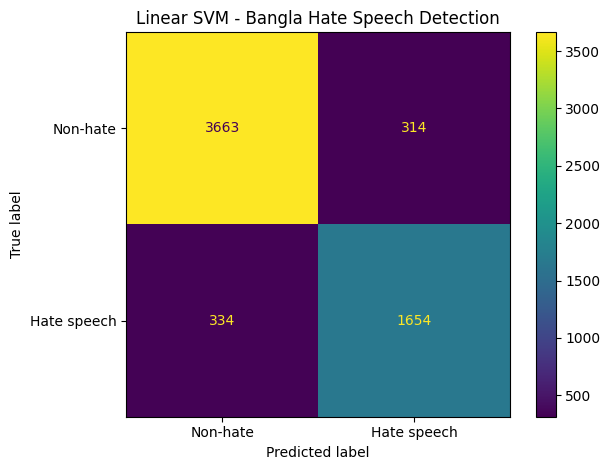

In [10]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_model = clean_models["Linear SVM"]

final_predictions = best_model.predict(X_test_clean)

print("FINAL LINEAR SVM CLASSIFICATION REPORT")
print(classification_report(
    y_test_clean,
    final_predictions,
    labels=[0, 1],
    target_names=["Non-hate", "Hate speech"],
    digits=4
))

cm = confusion_matrix(
    y_test_clean,
    final_predictions,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-hate", "Hate speech"]
).plot(values_format="d")

plt.title("Linear SVM - Bangla Hate Speech Detection")
plt.tight_layout()
plt.savefig("linear_svm_confusion_matrix.png", dpi=300)
plt.show()


In [11]:

from google.colab import files

clean_results_df.to_csv(
    "final_model_comparison.csv",
    index=False
)

files.download("final_model_comparison.csv")
files.download("linear_svm_confusion_matrix.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>